# Logistic Regression for Red Clump Stars

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 7 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In the earlier chapters we predicted continuous quantities, such as stellar parameters. Many questions in astronomy ask for a discrete class instead, because stars occupy distinct stages of evolution and galaxies fall into morphological types. Is this object a star or a galaxy? Is this transient a supernova or an active galactic nucleus? Is this star on the red giant branch, or has it evolved to the red clump phase?

Logistic regression links the linear methods that we know to classification. We apply a simple nonlinear transformation, the sigmoid function, to our linear model. The result is the probability that an object belongs to a class. A probability is useful for noisy astronomical data, where sharp boundaries between classes rarely exist.

In this tutorial we separate red clump (RC) stars from red giant branch (RGB) stars. The reason is the distance. Parallax measurements from missions such as Gaia gave accurate distances for nearby stars, but the fractional error of a parallax grows with distance. For stars beyond a few kiloparsecs, which include most stars of our Galaxy, we need other distance indicators.

RC stars are a good choice. They burn helium in their cores after the helium flash, the sudden ignition of the helium. The core of such a star ignites helium at nearly the same core mass, whatever its earlier evolution. RC stars are therefore standard candles, objects of known intrinsic brightness whose distances we can infer from their apparent magnitudes.

The use of RC stars depends on how well we can tell them from RGB stars. An RGB star climbs the giant branch while it burns hydrogen in a shell around an inert helium core. RGB stars populate a similar region of the temperature and gravity plane, but they have a wide range of luminosities. An RGB star taken for an RC star would get a large distance error. This classification therefore affects how well we can map the three-dimensional structure of our Galaxy.

Asteroseismology, the study of stellar oscillations, is the usual way to identify RC stars. It needs long and frequent photometric monitoring, from missions such as Kepler or TESS, so it covers only small fields. The onset of core helium burning also changes the temperature and the surface gravity of a star. Spectroscopic surveys such as the Apache Point Observatory Galactic Evolution Experiment (APOGEE) measure these properties for far more stars. We therefore train a classifier on stars with asteroseismic classes, using their spectroscopic and photometric measurements as features. It can then classify stars from these measurements alone.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Working knowledge of Python, with NumPy arrays and matplotlib plots
- Linear regression, with linear models and model parameters
- Probability and the likelihood
- Splitting data into training, validation and test sets

### Learning Objectives

After this tutorial you can do the following.

- Turn a linear model into a classifier with the sigmoid function
- Explain how the sigmoid converts a linear output into a probability
- Write batch and mini-batch gradient descent from scratch
- Evaluate a classifier on classes of unequal size with the recall, the precision and the balanced accuracy
- Set a probability threshold, and read the ROC curve and the AUC
- Tune the learning rate and the batch size on data that the final score does not use

We begin by importing the libraries and setting the plot style.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from sklearn.model_selection import train_test_split

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Set random seed for reproducibility
np.random.seed(42)

%matplotlib inline

## The APOGEE Data

We load an APOGEE sample with asteroseismic classes.

In [2]:
# Load the APOGEE dataset with asteroseismic classifications
data = np.load("../data/dataset_apogee_asteroseismic.npz")

# Feature matrix, with spectroscopic and photometric features, and labels (1 for RC, 0 for RGB)
X = data["data"]
t = data["label"]

# Print the numbers of stars
print(f"Stars = {len(t):,}, RGB = {np.sum(t == 0):,}, RC = {np.sum(t == 1):,}")

Stars = 2,855, RGB = 730, RC = 2,125


The labels come from Kepler asteroseismology, as in [Ting, Hawkins & Rix (2018)](https://ui.adsabs.harvard.edu/abs/2018ApJ...858L...7T/abstract). The period spacing of the mixed oscillation modes, which [Vrard et al. (2016)](https://ui.adsabs.harvard.edu/abs/2016A&A...588A..87V/abstract) measured, probes the core. It is above 250 s for an RC star, whose core burns helium, and below for an RGB star, whose core is inert. We take these classes as the correct labels. Each star has eight features from three kinds of measurement.

**Spectroscopic parameters** come from the spectrum of the star, which APOGEE observed.

- **Effective temperature (Teff)** is the temperature of a black body that emits the same power per unit surface area as the star.
- **Surface gravity (log g)** is the logarithm of the gravitational acceleration at the photosphere of the star. It relates to the mass and the radius of the star through $g = GM/R^2$.
- **Metallicity ([Fe/H])** is the base-10 logarithm of the iron to hydrogen number ratio of the star, relative to the Sun. A star with [Fe/H] = -1 has an iron to hydrogen ratio ten times lower than the Sun.

**Photometric measurements** are the near-infrared magnitudes J, H and K, apparent brightnesses in the photometric system of the Two Micron All Sky Survey (2MASS). They depend on both the distance and the intrinsic luminosity of the star.

**Sky coordinates (RA, Dec)** give the position of the star. We include them to test whether our classifier uses spatial information that it should not use.

We now plot the two populations in the plane of temperature and gravity.

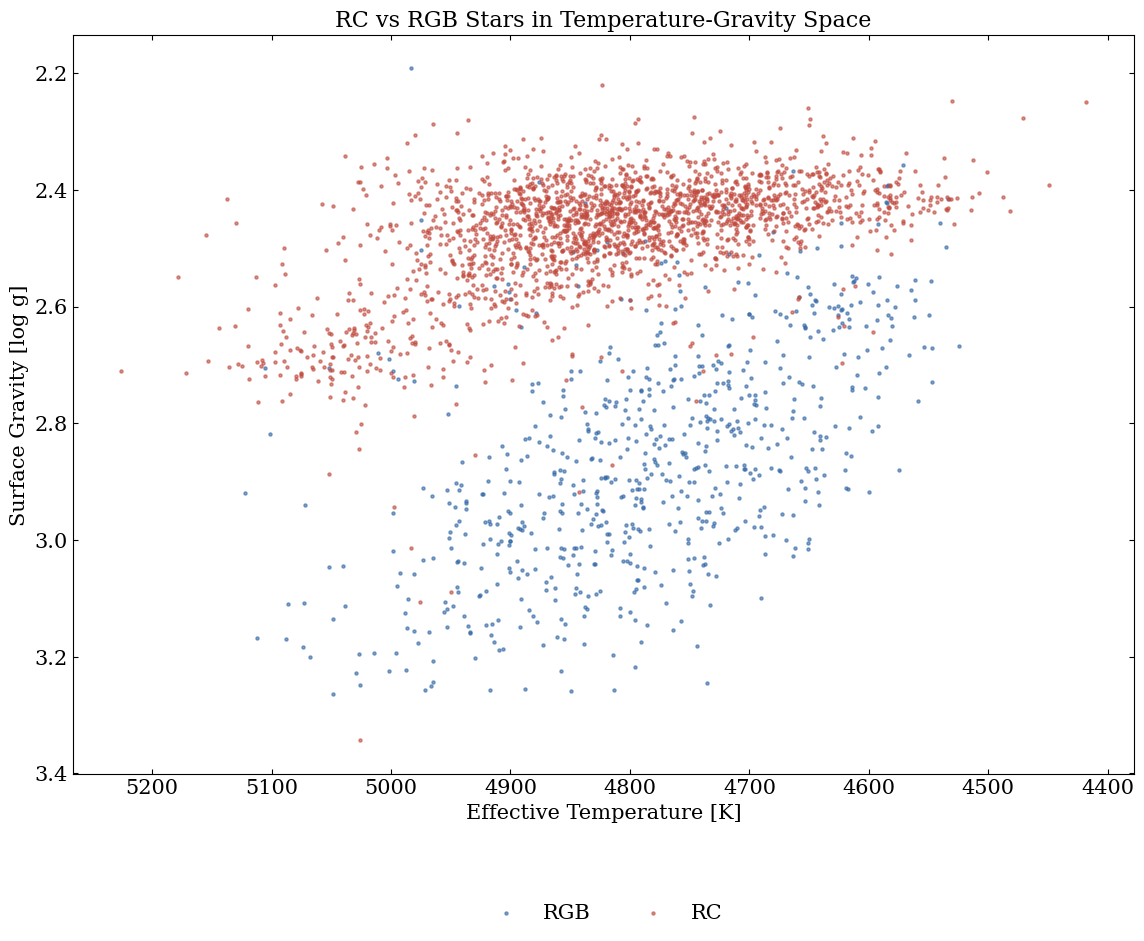

In [3]:
# Visualize the stellar populations in temperature-gravity space
plt.figure(figsize=(13.7, 9.6))

# Plot RGB stars (label = 0) in blue
plt.scatter(X[t == 0, 0], X[t == 0, 1], c='C0', s=5, alpha=0.6, label='RGB')

# Plot Red Clump stars (label = 1) in red
plt.scatter(X[t == 1, 0], X[t == 1, 1], c='C3', s=5, alpha=0.6, label='RC')

# Use the orientation of stellar astrophysics
plt.gca().invert_xaxis()  # Higher temperature on the left
plt.gca().invert_yaxis()  # Lower gravity (more evolved) at top
plt.xlabel('Effective Temperature [K]')
plt.ylabel('Surface Gravity [log g]')
plt.title('RC vs RGB Stars in Temperature-Gravity Space')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

RC stars (red points) cluster tightly around $\log g \approx 2.5$, because they all burn helium in their cores. RGB stars (blue points) span a broader range of surface gravities, mostly at a higher gravity than the RC stars. As a star ascends the giant branch, its radius increases and its surface gravity decreases steadily.

The two populations overlap at intermediate gravities, $\log g \approx 2.5$ to 2.8. There, ascending RGB stars and RC stars occupy nearly the same region. A single threshold in log g or in temperature would misclassify some of these stars, so we use a probabilistic approach. Logistic regression learns the probability that a star with given spectroscopic properties belongs to the RC population.

## From Linear to Logistic Regression

In earlier chapters we described continuous quantities, such as stellar parameters, as linear combinations of features. Classification needs another approach, because we predict discrete classes and not continuous values.

Consider a direct linear regression of our binary labels, 0 for RGB and 1 for RC. A linear model $\mathbf{w}^T\mathbf{x}$ can give any real number, but the labels are limited to 0 and 1. Worse, a prediction outside the interval [0, 1] has no meaning as a probability, because a probability cannot be negative or exceed one.

Logistic regression solves this with the sigmoid function (Section 7.3)

$$\sigma(z) = \frac{1}{1 + e^{-z}}.$$

This transformation maps any real number to the interval (0, 1), so the output is a valid probability. The function has three useful properties.

- **Monotonicity** means that a larger linear output gives a higher probability.
- **Symmetry** means that $\sigma(-z) = 1 - \sigma(z)$.
- **Smooth gradients** allow an efficient optimization.

For stellar classification, our model computes

$$P(\text{RC}|\mathbf{x}, \mathbf{w}) = \sigma(\mathbf{w}^T\mathbf{x}).$$

The linear term $\mathbf{w}^T\mathbf{x}$ is a weighted sum of the features, and it indicates the type of the star. We now code the sigmoid and plot it.

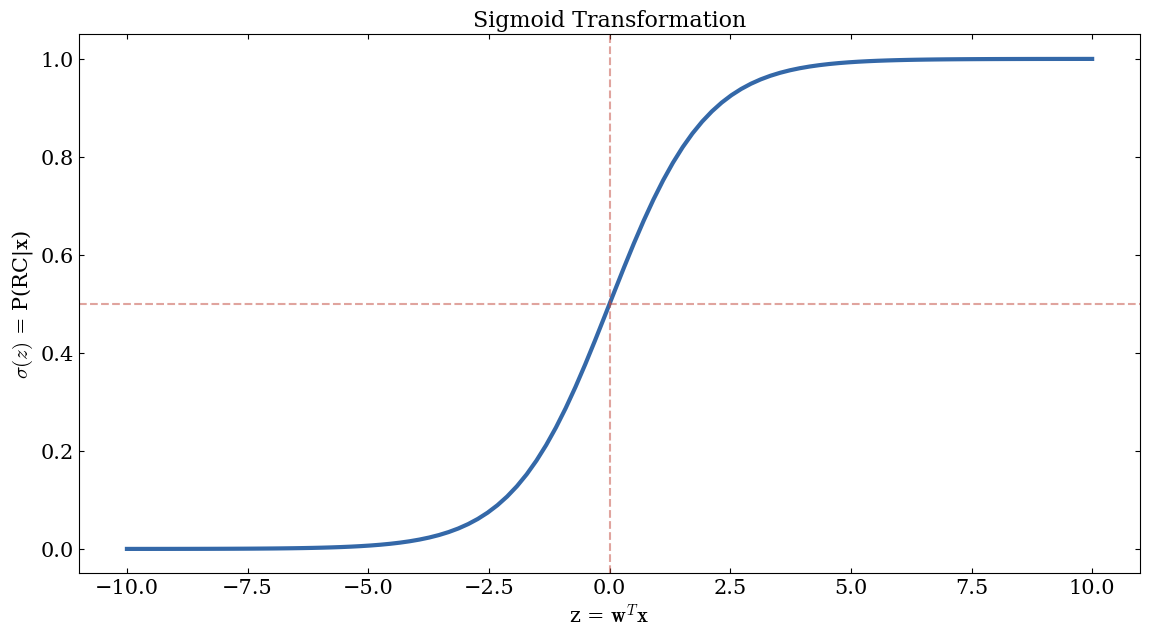

In [4]:
def sigmoid(z):
    """Return the sigmoid of z."""
    return 1 / (1 + np.exp(-z))

# Visualize the sigmoid function
z = np.linspace(-10, 10, 100)
plt.figure(figsize=(13.7, 7.0))
plt.plot(z, sigmoid(z), linewidth=3)
plt.axhline(y=0.5, color='C3', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='C3', linestyle='--', alpha=0.5)
plt.xlabel(r'z = $\mathbf{w}^T\mathbf{x}$')
plt.ylabel(r'$\sigma(z)$ = P(RC|$\mathbf{x}$)')
plt.title('Sigmoid Transformation')
plt.show()

The sigmoid has properties that suit a classification.

1. **Decision boundary at $z = 0$.** When $\mathbf{w}^T\mathbf{x} = 0$, the probability is 0.5, which is the decision threshold. A star with a positive linear output is more likely RC, and a negative value suggests RGB.
2. **Extreme probabilities for a large $|z|$.** As $|z|$ grows, the sigmoid approaches 0 or 1. A star with $z = 5$ gives $P(\text{RC}) \approx 0.993$, and a star with $z = -5$ gives $P(\text{RC}) \approx 0.007$.
3. **Gradient properties.** The derivative $\sigma'(z) = \sigma(z)(1-\sigma(z))$ is largest at $z = 0$ and vanishes for large $|z|$.

## Maximum Likelihood Formulation

To learn the best weights $\mathbf{w}$, we use the maximum likelihood principle (Section 7.6). The training data are $\{(\mathbf{x}_i, t_i)\}_{i=1}^N$, where $t_i \in \{0,1\}$ gives the true type of star $i$. We look for the weights that maximize the probability of the observed labels.

For one star with features $\mathbf{x}_i$ and true label $t_i$, the likelihood is

$$p(t_i|\mathbf{x}_i, \mathbf{w}) = y_i^{t_i}(1-y_i)^{1-t_i},$$

where $y_i = \sigma(\mathbf{w}^T\mathbf{x}_i)$ is the RC probability that our model predicts. This compact expression covers both cases.

- If $t_i = 1$ (an RC star), the likelihood is $y_i$.
- If $t_i = 0$ (an RGB star), the likelihood is $1-y_i$.

For independent observations the total likelihood is the product over all stars. We take the logarithm, which turns the product into a sum and avoids numerical underflow. We also take the negative and divide by $N$, so that the loss does not grow with the number of stars. This gives the negative log-likelihood loss

$$E(\mathbf{w}) = -\frac{1}{N}\sum_{i=1}^N \left[t_i \ln y_i + (1-t_i)\ln(1-y_i)\right].$$

This cross-entropy loss measures the difference between the predicted probabilities and the true labels. It is the objective of our optimization. We now code it, with a small constant that prevents the logarithm of zero.

In [5]:
def cost(w, X, t, N):
    """Return the average negative log-likelihood (the cross-entropy loss) of N stars."""
    z = X @ w  # linear output for every star
    y = sigmoid(z)

    # Add a small epsilon to prevent log(0)
    epsilon = 1e-15
    return -np.sum(t * np.log(y + epsilon) +
                   (1 - t) * np.log(1 - y + epsilon)) / N

## Gradient-Based Optimization

To minimize the loss, we use gradient descent. It adjusts the weights iteratively in the direction of the steepest decrease. The gradient of the loss with respect to the weights has a simple form (Section 7.7)

$$\nabla E(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^N (y_i - t_i)\mathbf{x}_i.$$

The gradient is the average prediction error $(y_i - t_i)$, weighted by the feature vector. Suppose that we predict a high RC probability ($y_i \approx 1$) for an RGB star ($t_i = 0$). The positive error then pushes the weights down for the features that are typical of that star.

The gradient is simple because the derivative of the sigmoid cancels against the derivatives of the logarithms in the cross-entropy loss. The error $(y_i - t_i)$ is close to 1 in magnitude when the model gives the wrong class a probability close to 1. It is close to 0 when the model gives the right class such a probability. We now code the gradient.

In [6]:
def grad(w, X, t, N):
    """Return the gradient of the average negative log-likelihood."""
    z = X @ w  # linear output for every star
    y = sigmoid(z)
    return X.T @ (y - t) / N  # average of the error times the features

## Preparing the Data

We split the stars into 80 percent training stars and 20 percent test stars. The split function of scikit-learn keeps the class shares equal in both sets. The search for the best settings below splits the training stars once more. The stars then divide into 60 percent fit stars, 20 percent validation stars and 20 percent test stars. The fit stars set the weights, the validation stars choose the settings, and the test stars give the final score.

We standardize the features to zero mean and unit variance, with the mean and the standard deviation of the training stars. A column of ones, the bias term, completes the feature matrix.

Standardizing the features has two purposes.

1. **Numerical stability.** Stellar parameters span very different scales, from temperatures of thousands of kelvin to metallicities in logarithmic units. Without standardization, a feature with a large scale can dominate the linear combination at the start of the descent.
2. **Efficiency of gradient descent.** Standardized features usually give the loss surface a rounder shape. One learning rate then suits all weights better, with fewer tiny steps along some directions and fewer overshoots along others.

We now split and standardize the stars.

In [7]:
# First split, into 80 percent training stars and 20 percent test stars, with the class shares kept
X_train, X_test, t_train, t_test = train_test_split(
    X, t, test_size=0.2, random_state=46, stratify=t
)

# Standardize with the mean and standard deviation of the training stars
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

# Add the bias term (a column of ones)
X_train = np.hstack((np.ones((len(t_train), 1)), (X_train - X_mean) / X_std))
X_test = np.hstack((np.ones((len(t_test), 1)), (X_test - X_mean) / X_std))

print(f"Training stars = {len(t_train)}, test stars = {len(t_test)}")

Training stars = 2284, test stars = 571


## Training with Batch Gradient Descent

We begin with batch gradient descent, which uses the entire training set to compute the gradient at each iteration. This gives the most accurate gradient estimate, but it can be expensive for large data sets. The update rule is the standard formula of gradient descent

$$\mathbf{w}^{(\tau+1)} = \mathbf{w}^{(\tau)} - \eta \nabla E(\mathbf{w}),$$

where $\tau$ counts the iterations and $\eta$ is the learning rate, a setting that controls the step size. A learning rate that is too small gives a very slow convergence. A learning rate that is too large may overshoot the minimum or even diverge.

We monitor the training loss and the test loss during the optimization. This gives us three pieces of information.

- The training loss measures how well we fit the labeled data.
- The test loss shows how well the model generalizes to stars that it has not seen.
- Overfitting shows as a divergence between the two losses.

We start from random weights and run 2,000 iterations with $\eta = 0.1$. At every iteration we record both losses.

In [8]:
# Train with batch gradient descent from random weights, and keep the losses of every iteration
lr = 0.1
n_iters = 2000
w_batch = np.random.randn(X_train.shape[1])

batch_train_loss = []
batch_test_loss = []
for i in range(n_iters):
    # One gradient step on all training stars, then the two losses
    w_batch -= lr * grad(w_batch, X_train, t_train, len(t_train))
    batch_train_loss.append(cost(w_batch, X_train, t_train, len(t_train)))
    batch_test_loss.append(cost(w_batch, X_test, t_test, len(t_test)))

We now plot the two learning curves.

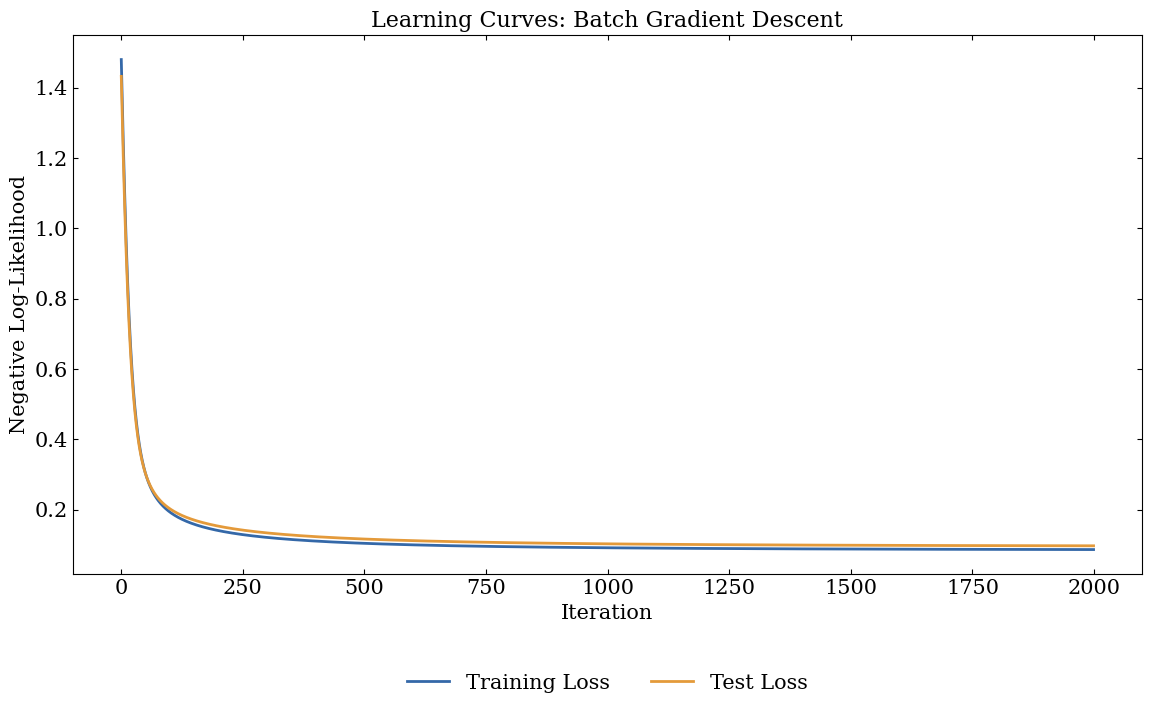

In [9]:
# Plot the learning curves
plt.figure(figsize=(13.8, 7.0))
plt.plot(batch_train_loss, label='Training Loss', linewidth=2)
plt.plot(batch_test_loss, label='Test Loss', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Negative Log-Likelihood')
plt.title('Learning Curves: Batch Gradient Descent')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The learning curves show the typical behavior of gradient descent. Both the training loss and the test loss fall quickly during the first few hundred iterations. The model learns the main separation between the RC and RGB populations in this phase. The curves then become nearly flat. The loss is convex and has a single minimum, so more iterations give little improvement.

The training loss and the test loss stay close together, which suggests that the model generalizes without overfitting. This is expected, because the number of features (8) is small compared with the number of training stars (about 2,300).

## Mini-batch Gradient Descent

Batch gradient descent converges steadily, but it becomes expensive for large data sets. Modern surveys such as APOGEE observe a very large number of stars. A gradient over the whole data set at each iteration is not practical.

Mini-batch gradient descent is a compromise. Instead of all $N$ training stars, we sample small random batches of size $M$ (typically 16 to 256). We compute the gradient over each batch

$$\nabla E_{\text{batch}}(\mathbf{w}) = \frac{1}{M}\sum_{i \in \text{batch}} (y_i - t_i)\mathbf{x}_i.$$

This approach has several advantages.

- **Speed.** We update the weights $N/M$ times per epoch, a pass through all training stars, and not once.
- **Stochastic updates.** The noise of the random batches can help an optimizer escape poor local minima. The loss of logistic regression has no such minima, so here the main gain is speed.
- **Memory use.** We need to load only a small subset of the data at a time.

We write the training loop as a function. Each epoch shuffles the stars, updates the weights on each mini-batch and records the training loss and the loss on a second set of stars. The function also keeps the weights with the lowest loss on the second set.

In [10]:
def train_minibatch(X_train, t_train, X_eval, t_eval, learning_rate, n_epochs, batch_size):
    """Train by mini-batch gradient descent and return the final weights, the weights with the lowest evaluation loss and the loss histories."""
    n_stars, n_features = X_train.shape
    w = np.random.normal(0, 1, n_features)  # Initialize from standard normal
    train_loss_history = []
    eval_loss_history = []
    best_w = w.copy()

    for epoch in range(n_epochs):
        # Shuffle the stars, so that each epoch has other mini-batches
        indices = np.random.permutation(n_stars)

        # Update the weights on each mini-batch, the last one may be smaller
        for start in range(0, n_stars, batch_size):
            batch = indices[start:start + batch_size]
            w = w - learning_rate * grad(w, X_train[batch], t_train[batch], len(batch))

        # Record the losses after each epoch
        train_loss_history.append(cost(w, X_train, t_train, len(t_train)))
        eval_loss_history.append(cost(w, X_eval, t_eval, len(t_eval)))

        # Keep the weights with the lowest evaluation loss so far
        if eval_loss_history[-1] == min(eval_loss_history):
            best_w = w.copy()

    return w, best_w, train_loss_history, eval_loss_history

We train with a learning rate of 0.1 and a batch size of 32 for 200 epochs.

In [11]:
# Train with mini-batch gradient descent
w_minibatch, _, train_hist, test_hist = train_minibatch(
    X_train, t_train, X_test, t_test, learning_rate=0.1, n_epochs=200, batch_size=32
)

We plot the learning curves and print the final losses.

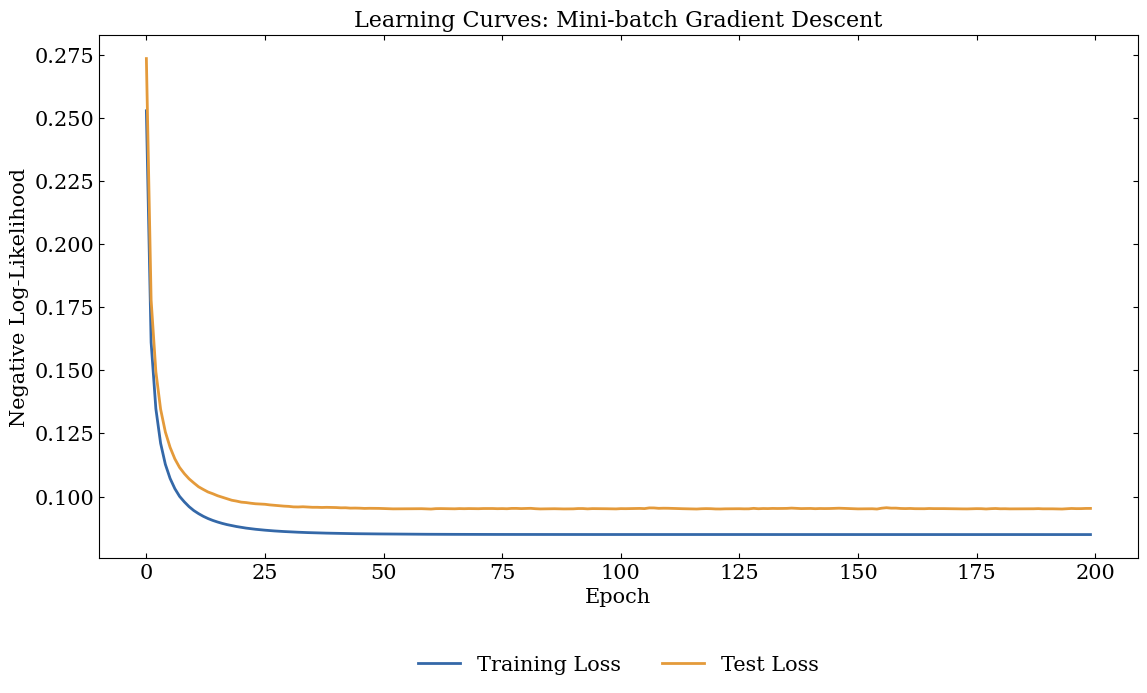

Final training loss = 0.0849, final test loss = 0.0953


In [12]:
# Plot the learning curves for mini-batch training
plt.figure(figsize=(13.4, 6.8))
plt.plot(train_hist, label='Training Loss', linewidth=2)
plt.plot(test_hist, label='Test Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Negative Log-Likelihood')
plt.title('Learning Curves: Mini-batch Gradient Descent')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

print(f"Final training loss = {train_hist[-1]:.4f}, final test loss = {test_hist[-1]:.4f}")

The mini-batch loss falls quickly and is nearly flat after about 30 epochs, which are 30 passes through the training stars. Batch gradient descent needs its 2,000 iterations, each one a pass through the stars, to reach a similar loss. The training loss and the test loss end close together, so the model generalizes.

## Model Evaluation

We have trained our classifier, so we now test how well it works. We ask two questions about the RC stars. How many of them does the model find? How clean is the sample that the model calls RC? A confusion matrix sorts the predictions into four kinds and answers both. We call the RC class the positive class, because it is the class that we want to find.

- A true positive (TP) is an RC star that the model calls RC.
- A true negative (TN) is an RGB star that the model calls RGB.
- A false positive (FP) is an RGB star that the model calls RC.
- A false negative (FN) is an RC star that the model calls RGB.

The first question is the **recall**. It is the fraction of the RC stars that the model finds, which are the RC stars that it calls RC

$$\text{Recall} = \frac{TP}{TP + FN}.$$

A false negative removes a reliable distance indicator from our sample. To keep the sample large, we want a high recall.

The second question is the **precision**. It is the fraction of the stars that the model calls RC that truly are RC

$$\text{Precision} = \frac{TP}{TP + FP}.$$

Like the recall, the precision refers to the positive class. A false positive, an RGB star taken for an RC star, gives a systematic error in the distance. A sample of distance indicators needs few RGB stars, so we want to limit the false positives and keep a high precision.

The **accuracy** gives one number for all predictions. It is the fraction of correct predictions

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}.$$

The accuracy can mislead when one class is much larger than the other. A classifier that always predicts the majority class gets a high accuracy but fails at the task. Here the RC stars outnumber the RGB stars.

The **balanced accuracy** avoids this problem. It averages the share of RC stars that the model calls RC and the share of RGB stars that it calls RGB. It therefore treats the classes equally whatever their size

$$\text{Balanced accuracy} = \frac{1}{2}\left(\frac{TP}{TP + FN} + \frac{TN}{TN + FP}\right).$$

We now code the prediction and the metrics.

In [13]:
def predict(w, X, threshold=0.5):
    """Return the predicted classes and the RC probabilities."""
    z = np.dot(X, w)
    probabilities = sigmoid(z)
    predictions = (probabilities >= threshold).astype(int)  # class 1 above the threshold
    return predictions, probabilities

def compute_metrics(t_true, t_pred):
    """Return the confusion matrix, the accuracy, the balanced accuracy, the recall and the precision."""

    # Compute the confusion matrix elements
    TP = np.sum((t_true == 1) & (t_pred == 1))
    TN = np.sum((t_true == 0) & (t_pred == 0))
    FP = np.sum((t_true == 0) & (t_pred == 1))
    FN = np.sum((t_true == 1) & (t_pred == 0))

    # Calculate the metrics
    accuracy = (TP + TN) / len(t_true)
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    rgb_correct = TN / (TN + FP) if (TN + FP) > 0 else 0  # share of the RGB stars that are called RGB
    balanced_acc = (recall + rgb_correct) / 2

    # Return all results in one dictionary
    return {
        'confusion_matrix': [[TN, FP], [FN, TP]],
        'accuracy': accuracy,
        'balanced_accuracy': balanced_acc,
        'recall': recall,
        'precision': precision
    }

We evaluate the mini-batch model on the test stars. We also score a baseline that calls every star RC, to see what the class sizes alone give.

In [14]:
# Evaluate on the test set
test_pred, test_probs = predict(w_minibatch, X_test)
metrics = compute_metrics(t_test, test_pred)

# Print the metrics and the confusion matrix
print(f"Recall = {metrics['recall']:.3f}, precision = {metrics['precision']:.3f}")
print(f"Accuracy = {metrics['accuracy']:.3f}, balanced accuracy = {metrics['balanced_accuracy']:.3f}")
confusion = metrics['confusion_matrix']
print(f"\n{'':<12}{'Predicted RGB':>16}{'Predicted RC':>16}")
print(f"{'Actual RGB':<12}{confusion[0][0]:>16}{confusion[0][1]:>16}")
print(f"{'Actual RC':<12}{confusion[1][0]:>16}{confusion[1][1]:>16}")

# Score the baseline that calls every star RC
baseline = compute_metrics(t_test, np.ones(len(t_test), dtype=int))
print(f"\nEvery star called RC: accuracy = {baseline['accuracy']:.3f}, "
      f"balanced accuracy = {baseline['balanced_accuracy']:.3f}")

Recall = 0.988, precision = 0.977
Accuracy = 0.974, balanced accuracy = 0.960

               Predicted RGB    Predicted RC
Actual RGB               136              10
Actual RC                  5             420

Every star called RC: accuracy = 0.744, balanced accuracy = 0.500


The model finds almost all RC stars, with a recall of 0.988. The precision is 0.977, so about 2 percent of the stars that the model calls RC are RGB stars. They would give wrong distances in a sample of RC distance indicators. The accuracy is high, and the balanced accuracy is a little lower, because the model errs more often on the smaller RGB class.

The baseline shows why we need the balanced accuracy. The RC stars are 74 percent of the test stars. Calling every star RC therefore gives an accuracy of 0.744 and a balanced accuracy of only 0.5. The model is far above both values.

We also look at the predicted probabilities. The histogram shows them separately for the true RC stars and the true RGB stars.

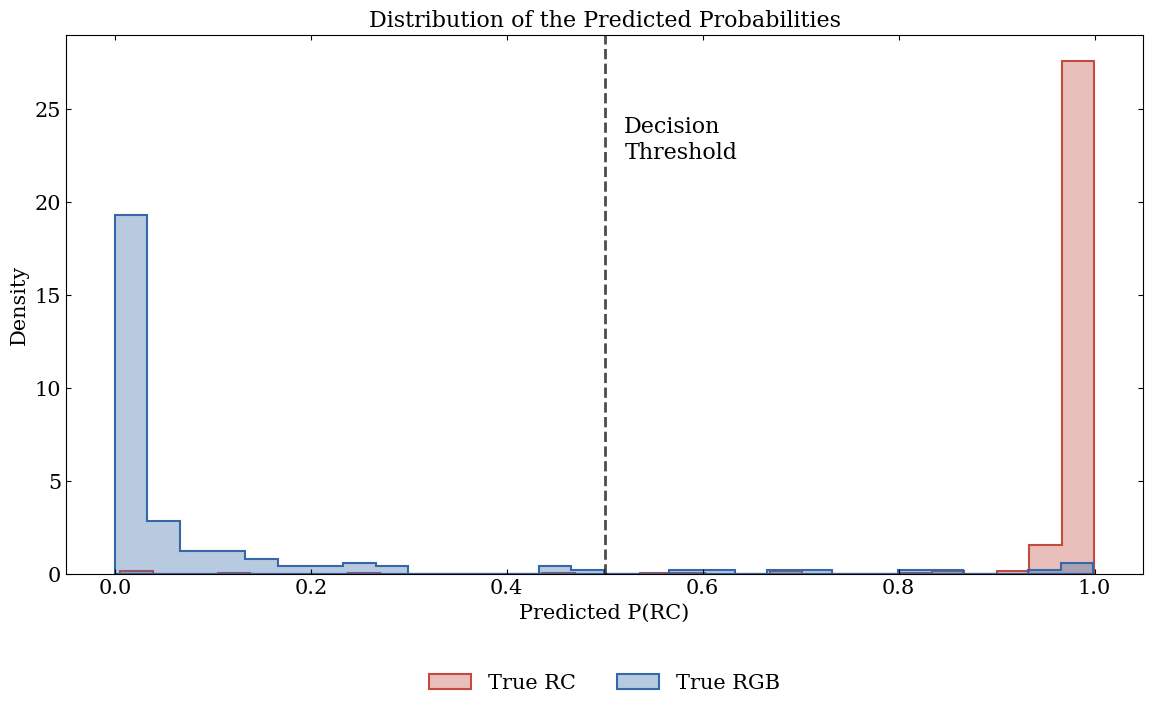

In [15]:
# Visualize the distribution of the predicted probabilities
plt.figure(figsize=(13.9, 7.0))

# Create a histogram for the true RC stars
plt.hist(test_probs[t_test == 1], bins=30, label='True RC', density=True,
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)

# Create a histogram for the true RGB stars
plt.hist(test_probs[t_test == 0], bins=30, label='True RGB', density=True,
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)

# Add a vertical line at the decision threshold
plt.axvline(x=0.5, color='black', linestyle='--', linewidth=2, alpha=0.7)
plt.text(0.52, plt.ylim()[1]*0.85, 'Decision\nThreshold', fontsize=16, va='top')

# Label the axes and add a legend
plt.xlabel('Predicted P(RC)')
plt.ylabel('Density')
plt.title('Distribution of the Predicted Probabilities')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The distribution of the probabilities shows how well our model separates the two populations. True RC stars (red) cluster near the probability 1, and true RGB stars (blue) concentrate near 0. The few stars between the two peaks are the most difficult cases. Their spectroscopic parameters place them in the region where the populations overlap. They deserve special attention in astronomical applications, because they are the stars most likely to be misclassified and to introduce systematic errors in distances.

## The Probability Threshold and the ROC Curve

So far we call a star RC when its probability is at least 0.5. The stars that we call RC form our RC sample. This threshold is a choice, and the best value depends on the use of the sample. A sample of distance indicators needs few RGB stars, so it can use a higher threshold. A higher threshold removes RGB stars from the RC sample, but it also loses RC stars.

We measure this trade-off with the recall and the precision. The recall is the fraction of all RC stars that are in the RC sample. The precision is the fraction of the RC sample that are RC stars. A higher threshold raises the precision and lowers the recall.

A third rate counts the RGB stars that we let in. The **false positive rate** (FPR) is the fraction of the RGB stars that we call RC

$$\text{FPR} = \frac{FP}{FP + TN}.$$

The recall is also called the true positive rate.

We apply five thresholds to the probabilities of the mini-batch model on the test stars, and we list the confusion matrix and the three rates. We only look at the trade-off and do not choose a threshold, so no choice uses the test stars.

In [16]:
def confusion_counts(threshold):
    """Return TN, FP, FN and TP of the test stars for one probability threshold."""
    threshold_pred, _ = predict(w_minibatch, X_test, threshold)
    (TN, FP), (FN, TP) = compute_metrics(t_test, threshold_pred)['confusion_matrix']
    return TN, FP, FN, TP

# Apply several probability thresholds to the test stars of the mini-batch model
print(f"{'Threshold':>9}{'TN':>6}{'FP':>5}{'FN':>5}{'TP':>6}{'Recall':>9}{'FPR':>8}{'Precision':>11}")
for threshold in [0.3, 0.5, 0.7, 0.9, 0.99]:
    TN, FP, FN, TP = confusion_counts(threshold)
    print(f"{threshold:>9}{TN:>6}{FP:>5}{FN:>5}{TP:>6}{TP / (TP + FN):>9.3f}{FP / (FP + TN):>8.3f}{TP / (TP + FP):>11.3f}")

Threshold    TN   FP   FN    TP   Recall     FPR  Precision
      0.3   133   13    4   421    0.991   0.089      0.970
      0.5   136   10    5   420    0.988   0.068      0.977
      0.7   139    7    9   416    0.979   0.048      0.983
      0.9   142    4   12   413    0.972   0.027      0.990
     0.99   144    2  171   254    0.598   0.014      0.992


A higher threshold gives fewer false positives, so the false positive rate falls and the precision rises. The precision rises from 0.977 at 0.5 to 0.990 at 0.9. The price is more false negatives, which are RC stars that we lose, so the recall falls. At 0.99 the model loses 171 of the 425 RC stars. A lower threshold does the opposite. It keeps more RC stars and lets in more RGB stars.

The five rows are five points on one curve of this trade-off. The receiver operating characteristic (ROC) curve shows the whole curve. It plots the recall against the false positive rate for every threshold. Both are fractions within one class, so the curve does not change when one class is larger than the other.

The threshold moves the point along the curve. A low threshold calls many stars RC. The recall and the false positive rate are then both high, and the point lies at the upper right. A high threshold calls few stars RC, so both are low and the point lies at the lower left. A classifier that guesses at random gives the diagonal. A good classifier reaches a high recall at a low false positive rate, so its curve lies near the upper left corner.

We now compute the recall and the false positive rate for the test stars.

In [17]:
# Use every distinct probability as a threshold, and 1.1 so that the curve reaches the lower left corner
thresholds = np.append(np.unique(test_probs), 1.1)
tpr = np.zeros(len(thresholds))
fpr = np.zeros(len(thresholds))
for i, threshold in enumerate(thresholds):
    TN, FP, FN, TP = confusion_counts(threshold)
    tpr[i] = TP / (TP + FN)  # the recall, which is the true positive rate
    fpr[i] = FP / (FP + TN)

We now plot the ROC curve, the diagonal of random guesses and the five thresholds of the table.

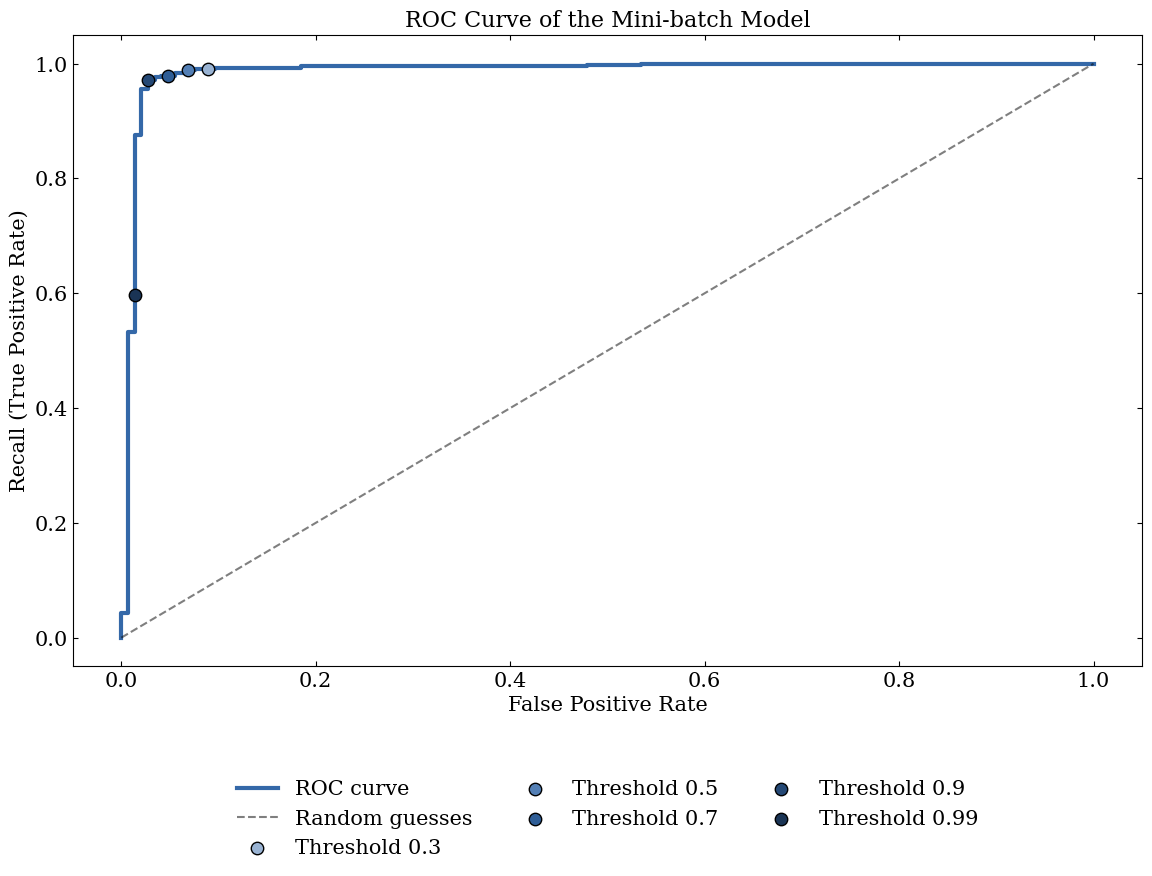

In [18]:
# Plot the ROC curve and the diagonal of random guesses
plt.figure(figsize=(13.8, 8.2))
plt.plot(fpr, tpr, linewidth=3, label='ROC curve')
plt.plot([0, 1], [0, 1], '--', color='k', alpha=0.5, label='Random guesses')

# Mark the five thresholds of the table
for threshold, color in zip([0.3, 0.5, 0.7, 0.9, 0.99], plt.colormaps['book_blue'](np.linspace(0.25, 0.95, 5))):
    TN, FP, FN, TP = confusion_counts(threshold)
    plt.scatter(FP / (FP + TN), TP / (TP + FN), s=80, color=color,
                edgecolors='black', zorder=3, label=f'Threshold {threshold}')

# Label the axes, add the title, and the legend
plt.xlabel('False Positive Rate')
plt.ylabel('Recall (True Positive Rate)')
plt.title('ROC Curve of the Mini-batch Model')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The curve rises steeply and stays close to the upper left corner, far from the diagonal, so the classifier separates the two classes well. The marks for the thresholds 0.3 to 0.9 lie close together near the corner, with a recall above 0.97. The mark for 0.99 lies far below them, because the model loses many RC stars there.

We can summarize how close the curve lies to the upper left corner by the area under it, the AUC. It is 0.5 for random guesses and 1 for a perfect classifier. The AUC does not depend on the threshold, so it is a good way to compare different classifiers. We use it below to compare the settings of our own classifier.

The AUC has a direct meaning. Take one RC star and one RGB star. A good classifier gives the RC star the higher probability P(RC). The AUC is the fraction of all such pairs in which it does.

We count these pairs. We also sum the thin strips under the curve, to check that the two agree. Each strip lies between two neighboring thresholds. Its width is the step of the false positive rate, and its height is the mean recall at the two ends.

In [19]:
def auc_score(probabilities, labels):
    """Return the fraction of the pairs of an RC star and an RGB star in which the RC star has the higher probability."""

    # Split the probabilities by the true class
    rc_probs = probabilities[labels == 1]
    rgb_probs = probabilities[labels == 0]
    return np.mean(rc_probs[:, None] > rgb_probs[None, :])  # compare every RC star with every RGB star

# The same area from the curve, as thin strips between neighboring thresholds
widths = fpr[:-1] - fpr[1:]  # step of the false positive rate, which falls as the threshold rises
heights = (tpr[:-1] + tpr[1:]) / 2  # mean recall at the two ends of the step
print(f"Fraction of ordered pairs = {auc_score(test_probs, t_test):.4f}, "
      f"area under the curve = {np.sum(widths * heights):.4f}")

Fraction of ordered pairs = 0.9858, area under the curve = 0.9858


The two values agree. The AUC is 0.986, close to the value 1 of a perfect classifier, so the model puts almost all pairs in the right order. A survey can read the curve to find the threshold that keeps enough RC stars at the false positive rate that it accepts.

## Hyperparameter Optimization

Our first model used hyperparameters that we fixed in advance. Hyperparameters are settings that control the training and that the data do not determine. Two of them matter most for mini-batch gradient descent.

1. **Learning rate ($\eta$).** It controls the step size in parameter space. A value that is too small gives a very slow convergence, and a value that is too large causes instability or divergence.
2. **Batch size ($M$).** It sets the number of stars that estimate each gradient. Smaller batches increase the stochasticity but reduce the accuracy of the gradient.

These hyperparameters interact. Small batches give noisier gradients, which can need a smaller learning rate for stability. Large batches give accurate gradients but make fewer updates per epoch.

We explore them with a grid search. The threshold is a separate choice, so we score each model by the AUC, which does not depend on it. We train a model for 100 epochs for each combination. We trace the validation loss after every epoch and keep the weights with the lowest validation loss. The combination with the highest AUC of these weights on the validation stars wins (Section 4.7).

We split the training stars for this into 75 percent fit stars and 25 percent validation stars. Of all stars, 60 percent are then fit stars, 20 percent validation stars and 20 percent test stars. The fit stars set the weights. The test stars take no part in the choice, so they stay a fair test of the final model.

In [20]:
# Define the hyperparameter grid
learning_rate_options = [0.001, 0.01, 0.1, 0.5]
batch_size_options = [16, 32, 64, 128, 256]

# Second split, of the training stars into 75 percent fit stars and 25 percent validation stars
fit_index, val_index = train_test_split(
    np.arange(len(t_train)), test_size=0.25, random_state=42, stratify=t_train
)
X_fit, t_fit = X_train[fit_index], t_train[fit_index]
X_val, t_val = X_train[val_index], t_train[val_index]

# Train on the fit stars and score the AUC of the best weights on the validation stars
val_auc_results = {}
best_val_auc = 0
for lr in learning_rate_options:
    for batch_size in batch_size_options:
        _, w_best, _, _ = train_minibatch(X_fit, t_fit, X_val, t_val, lr, 100, batch_size)
        _, val_probs = predict(w_best, X_val)
        val_auc_results[(lr, batch_size)] = auc_score(val_probs, t_val)

        # Keep the pair with the highest validation AUC, with its best weights
        if val_auc_results[(lr, batch_size)] > best_val_auc:
            best_val_auc = val_auc_results[(lr, batch_size)]
            best_lr = lr
            best_batch_size = batch_size
            w_final = w_best

print(f"Best: learning rate {best_lr}, batch size {best_batch_size}, "
      f"validation AUC {best_val_auc:.4f}")

Best: learning rate 0.01, batch size 32, validation AUC 0.9817


We show the validation AUC of every combination as a heatmap, and we mark the best combination with a star. The color scale starts at 0.97, so all lower values share the lightest color.

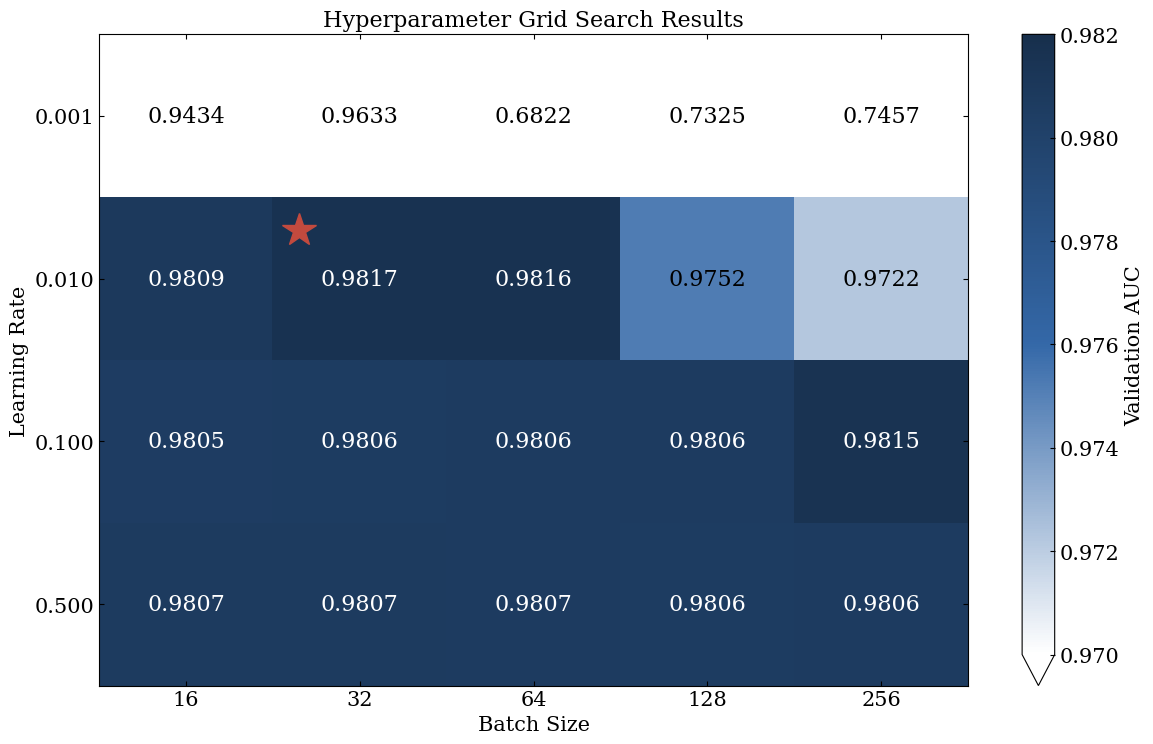

In [21]:
# Create a heatmap of the hyperparameter search results
plt.figure(figsize=(12.2, 7.7))

# Convert the results to matrix form
auc_matrix = np.zeros((len(learning_rate_options), len(batch_size_options)))
for i, lr in enumerate(learning_rate_options):
    for j, batch_size in enumerate(batch_size_options):
        auc_matrix[i, j] = val_auc_results[(lr, batch_size)]

# Create the heatmap, with a higher AUC in a darker color and a color scale that starts at 0.97
im = plt.imshow(auc_matrix, aspect='auto', cmap='book_blue', vmin=0.97, vmax=0.982)
plt.colorbar(im, label='Validation AUC', extend='min')

# Add annotations, in white on the dark cells and in black on the light ones
for i in range(len(learning_rate_options)):
    for j in range(len(batch_size_options)):
        plt.text(j, i, f'{auc_matrix[i, j]:.4f}', ha="center", va="center",
                 color="white" if np.mean(im.cmap(im.norm(auc_matrix[i, j]))[:3]) < 0.5 else "black", fontsize=16)

# Customize the plot
plt.xlabel('Batch Size')
plt.ylabel('Learning Rate')
plt.title('Hyperparameter Grid Search Results')
plt.xticks(range(len(batch_size_options)), batch_size_options)
plt.yticks(range(len(learning_rate_options)),
           [f'{lr:.3f}' for lr in learning_rate_options])

# Mark the best parameters, a little off the center so that the number stays readable
best_i = learning_rate_options.index(best_lr)
best_j = batch_size_options.index(best_batch_size)
plt.plot(best_j - 0.35, best_i - 0.3, '*', color='C3', markersize=25)

plt.tight_layout()
plt.show()

We read three points from the heatmap.

1. **Learning rate effects.** The smallest learning rate, 0.001, gives poor results, likely because 100 epochs are too few for the optimizer to make enough progress. The three larger values give an AUC between 0.972 and 0.982.
2. **Batch size effects.** At the small learning rates, 0.001 and 0.01, large batches give a lower AUC than small batches. A larger batch makes fewer updates in a fixed number of epochs. At the learning rates 0.1 and 0.5 the batch size matters little.
3. **Interaction effects.** The best learning rate depends on the batch size. Small batches give noisy gradients and do well with a smaller learning rate, and large batches need a larger one. The interaction is modest for 0.1, which gives an AUC of about 0.98 for all batch sizes.

## Final Model

The best weights of the best combination are our final model. They come from the fit stars, so the validation stars stay validation stars, and the test stars stay untouched until now. We score the model on the test stars, with the accuracy, the balanced accuracy and the AUC.

In [22]:
# Evaluate the final model on the test stars
test_pred_final, test_probs_final = predict(w_final, X_test)
final_metrics = compute_metrics(t_test, test_pred_final)
print(f"Accuracy = {final_metrics['accuracy']:.3f}, balanced accuracy = {final_metrics['balanced_accuracy']:.3f}, "
      f"AUC = {auc_score(test_probs_final, t_test):.4f}")

Accuracy = 0.968, balanced accuracy = 0.945, AUC = 0.9851


The final model scores comparably to the first model on the test stars, with an accuracy of 0.968 and an AUC of 0.985.

## Visualizing the Decision Boundary

To see how our model separates RC and RGB stars, we visualize the decision boundary in the plane of temperature and gravity. These are the two main spectroscopic parameters. The model has more features, so we set the other features to their median values. This gives a slice through the high-dimensional feature space.

The decision boundary lies where $P(\text{RC}) = 0.5$, which corresponds to $\mathbf{w}^T\mathbf{x} = 0$. We evaluate the predictions of our model on a grid of temperatures and gravities. This maps the regions where the model gives a probability close to 1 for the RC class or the RGB class.

In [23]:
# Indices of temperature and gravity in the feature matrix, after the bias term
teff_idx, logg_idx = 1, 2

# Grid of temperature and gravity values in the standardized space
xx, yy = np.meshgrid(
    np.linspace(X_test[:, teff_idx].min() - 0.5, X_test[:, teff_idx].max() + 0.5, 200),
    np.linspace(X_test[:, logg_idx].min() - 0.5, X_test[:, logg_idx].max() + 0.5, 200)
)

# Feature matrix of the grid points, with the other features at their median values
X_mesh = np.zeros((xx.size, X_test.shape[1]))
X_mesh[:, 0] = 1  # Bias term
X_mesh[:, teff_idx] = xx.ravel()
X_mesh[:, logg_idx] = yy.ravel()
X_mesh[:, 3:] = np.median(X_test[:, 3:], axis=0)

# Probability of RC on the grid
_, probs = predict(w_final, X_mesh)
Z = probs.reshape(xx.shape)

We now draw the probability as filled contours, the decision boundary as a black line and the test stars as points. An orange cross marks each star that the model classifies wrongly.

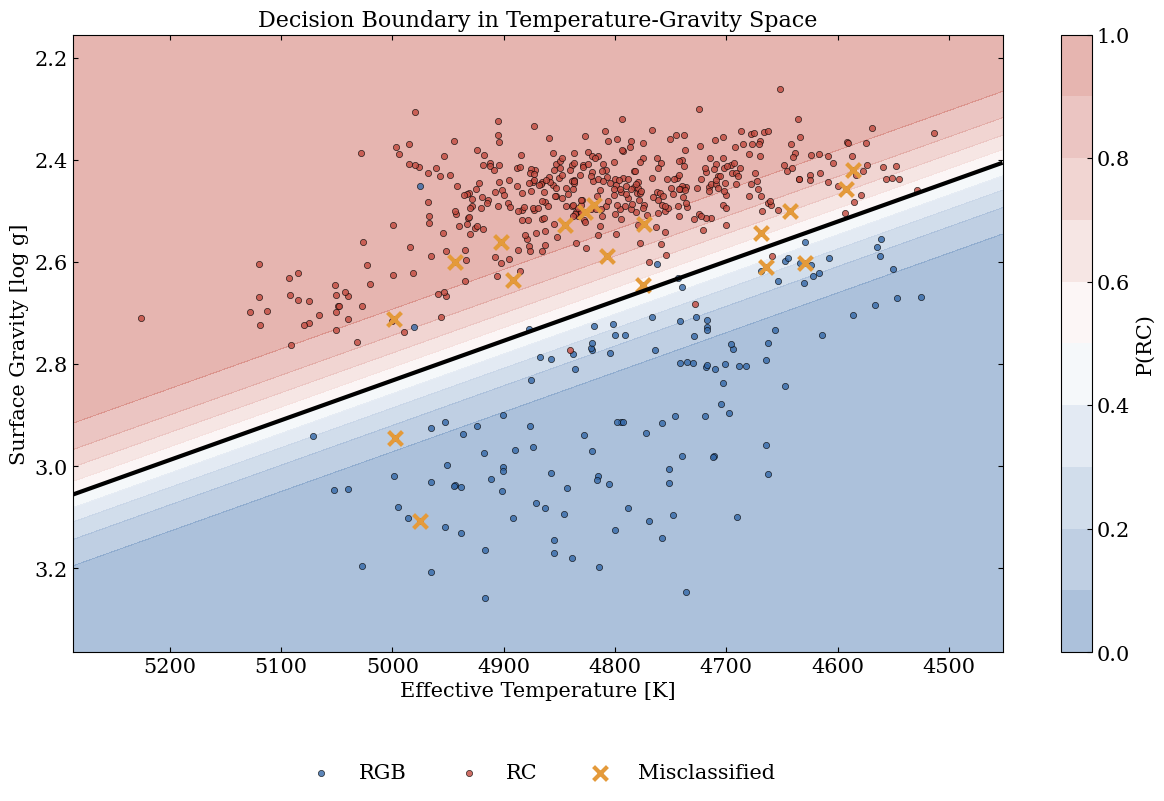

In [24]:
# Convert back to physical units for plotting
xx_denorm = xx * X_std[0] + X_mean[0]
yy_denorm = yy * X_std[1] + X_mean[1]
X_test_teff = X_test[:, teff_idx] * X_std[0] + X_mean[0]
X_test_logg = X_test[:, logg_idx] * X_std[1] + X_mean[1]

plt.figure(figsize=(12.7, 8.3))

# Plot the probability as light filled contours, as the class maps of the book, and the decision boundary
contour = plt.contourf(xx_denorm, yy_denorm, Z,
                       levels=np.linspace(0, 1, 11),
                       cmap='book_div', alpha=0.45)
plt.colorbar(contour, label='P(RC)')
plt.contour(xx_denorm, yy_denorm, Z, levels=[0.5],
            colors='black', linewidths=3)

# Plot the test stars
plt.scatter(X_test_teff[t_test == 0], X_test_logg[t_test == 0],
            c='C0', s=20, alpha=0.8, edgecolors='black',
            linewidth=0.5, label='RGB')
plt.scatter(X_test_teff[t_test == 1], X_test_logg[t_test == 1],
            c='C3', s=20, alpha=0.8, edgecolors='black',
            linewidth=0.5, label='RC')

# Mark the misclassified stars
misclassified = (test_pred_final != t_test)
plt.scatter(X_test_teff[misclassified], X_test_logg[misclassified],
            marker='x', s=100, c='C1', linewidths=3,
            label='Misclassified')

# Label the axes, add a legend and use the usual orientation
plt.xlabel('Effective Temperature [K]')
plt.ylabel('Surface Gravity [log g]')
plt.title('Decision Boundary in Temperature-Gravity Space')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The black contour marks $P(\text{RC}) = 0.5$, the decision threshold. In the space of the eight features, the condition $\mathbf{w}^T\mathbf{x} = 0$ describes a flat surface, a hyperplane. Our plot is a two-dimensional slice of that space, with the other six features fixed. A hyperplane cuts a two-dimensional slice along a straight line, so the contour is a line. The sigmoid does not bend the boundary (Section 7.3).

We read four things from the plot.

1. **Physical coherence.** RC stars (red) cluster in a compact region around $\log g \approx 2.5$, and RGB stars (blue) spread over higher gravities. The model learns this separation in gravity without any explicit physical constraint.
2. **Regions of extreme probability.** The darkest red and blue regions mark probabilities close to 1 for one class. The model gives these to the stars far from the boundary, the RGB stars at high gravity and the tightly clustered RC stars.
3. **Ambiguous zone.** The gradient region around the decision boundary holds the most difficult classifications. A small measurement error could move a star to the other side of the boundary here. The probability of such a star lies near 0.5, so its two classes are almost equally probable.
4. **Misclassifications.** Orange crosses mark the stars that the model classifies wrongly. Most of them lie on the side of the line that belongs to the other class, and one lies on the correct side. The model uses all eight features, and the line is only the slice for the median values of the other six. A star with other values has its own slice, a parallel line that lies a little higher or lower in the plot.

## Summary

This tutorial showed how logistic regression classifies astronomical objects, with two classes of giant stars as the example. We transformed a linear model with the sigmoid function and obtained a probabilistic classifier. It reaches a high accuracy.

Our main lessons follow.

1. **Probabilistic approach.** Logistic regression gives the probability that an object belongs to a class. When the classes feed a later analysis, these probabilities give the chance of each class for each object, and later steps can use them. A threshold on the probability sets the balance between a clean sample and a complete one. The ROC curve shows this balance for all thresholds.
2. **Optimization methods.** We implemented batch and mini-batch gradient descent from scratch. Mini-batches scale to modern surveys with a very large number of objects, because each update needs only a small part of the data. For this convex loss the main gain is speed.
3. **Evaluation and hyperparameters.** The confusion matrix, the recall and the precision tell more than the accuracy. The balanced accuracy corrects the accuracy for classes of unequal size. The AUC scores a classifier without a choice of threshold. We chose the learning rate and the batch size with a grid search on the AUC of validation stars. The final model has the weights with the lowest validation loss, and we scored it on test stars.

The same approach can apply to other classification problems in astronomy. It needs a linear boundary that separates the classes well. Logistic regression gives a principled and interpretable baseline against which we can evaluate more complex methods.